This task is similar to my Covid-19 detection that uses a chest X-ray scan to detect Covid, Viral Pneumonia, or Normal. Both are classification tasks that are using images as input. The steps taken will be different due to different datasets, binary classification instead of ternary classification, and increased knowledge, but this project will be my main inspiration source.

Link to Past Reference Project - https://github.com/gupta-reyansh/Covid_Detection_From_Chext_Xrays

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import random
import matplotlib.image as mpimg
import math 
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

height, width = 224, 224
batch_size=32
#To load images for viewing and test images
def generate_data(DIR):
    datagen = ImageDataGenerator(rescale=1./255.,validation_split=0.1)
    generator = datagen.flow_from_directory(
        DIR,
        batch_size=batch_size,
        shuffle=True,                                                          
        seed=42,
        class_mode='binary',
        target_size=(height, width),
        classes={'Benign': 0, 'Malignant': 1},
    )
    return generator
# generating testing and training data
TRAINING_DIR = '/kaggle/input/datasets/ailearner-researchlab/melanoma-skin-cancer-dataset-benign-vs-malignant/train'
TESTING_DIR = '/kaggle/input/datasets/ailearner-researchlab/melanoma-skin-cancer-dataset-benign-vs-malignant/test'

train_data = generate_data(TRAINING_DIR)                                       
test_data = generate_data(TESTING_DIR)                                         

Found 11879 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.


Melanoma is a form of skin cancer that can be fatal, and early detection can increase chances of survival. Benign (non-cancerous) skin lesions and malignant(cancerous) skin lesions look similar and can be difficult to differentiate. Machine learning can be utilized to assist doctors in detecting whether the skin lesion is benign or malignant.

The dataset contains 13,879 dermoscopic images for classification of skin lesions into benign or malignant.

There are 11,879 Training Images(6289 Benign, 5590 Malignant)

There are 2000 Test Images(1000 Benign, 1,000 Malignant)

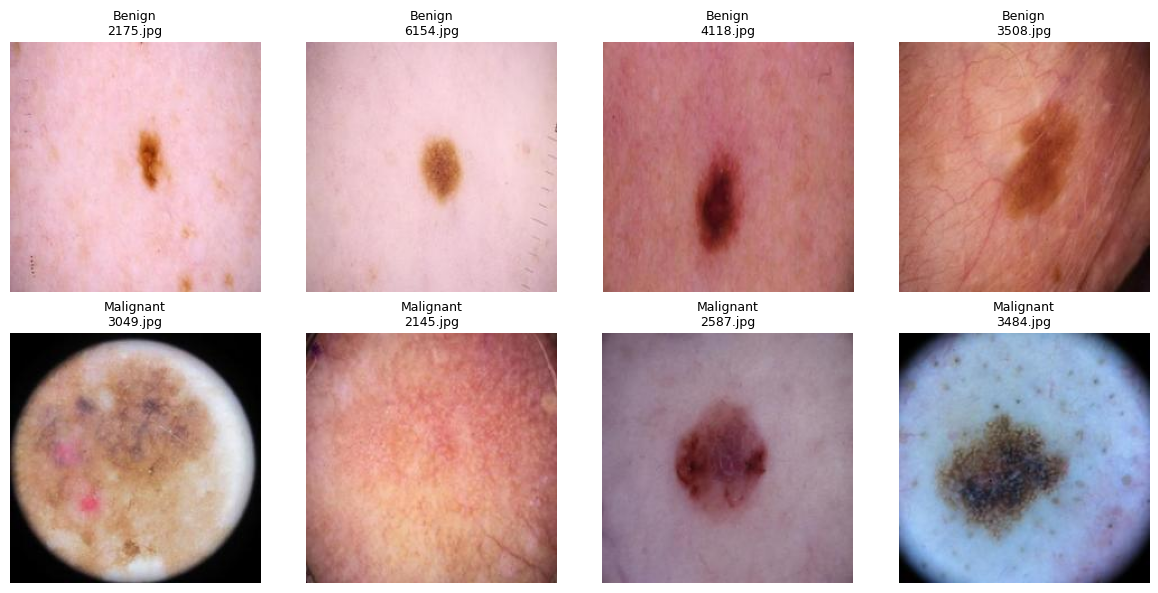

In [ ]:
def plot_random_images(NumOfEachType, data_dir=TRAINING_DIR, classes=("Benign", "Malignant")):
    fig, axes = plt.subplots(len(classes), NumOfEachType,
                             figsize=(3 * NumOfEachType, 3 * len(classes)),
                             squeeze=False)

    for row, cls in enumerate(classes):
        folder = os.path.join(data_dir, cls)
        files = [f for f in os.listdir(folder) if f.lower().endswith(".jpg")]
        picks = random.sample(files, min(NumOfEachType, len(files)))

        for col in range(NumOfEachType):
            ax = axes[row][col]
            ax.axis("off")
            if col < len(picks):
                ax.imshow(mpimg.imread(os.path.join(folder, picks[col])))
                ax.set_title(f"{cls}\n{picks[col]}", fontsize=9)

    plt.tight_layout()
    plt.show()

plot_random_images(4)

In [ ]:

def generate_data_augmented(DIR):
    datagen = ImageDataGenerator(                                              
        rescale=1./255.,                                                       
        zoom_range=0.2,         
        rotation_range=25,     
        width_shift_range=0.15,     
        height_shift_range=0.15,  
        horizontal_flip = True,
        validation_split=0.1
    )
    generator = datagen.flow_from_directory(
        TRAINING_DIR,                                                          
        batch_size=batch_size,                                                
        seed=42,
        shuffle=True,
        class_mode='binary',                                                   
        target_size=(height, width),                                         
        classes={'Benign': 0, 'Malignant': 1}, 
        subset='training'
    )
    return generator

aug_train_data = generate_data_augmented(TRAINING_DIR)

val_datagen = ImageDataGenerator(
    rescale=1./255.,
    validation_split=0.1)
    
val_data = val_datagen.flow_from_directory(
    TRAINING_DIR,
    batch_size=batch_size,
    seed=42,
    shuffle=False,
    class_mode='binary',
    target_size=(height, width),
    classes={'Benign': 0, 'Malignant': 1},
    subset='validation'
)

Found 10692 images belonging to 2 classes.
Found 1187 images belonging to 2 classes.


In [ ]:


from IPython.display import clear_output
from sklearn.metrics import roc_auc_score, roc_curve

class LivePlot(tf.keras.callbacks.Callback):
    def __init__(self, val_generator):
        super().__init__()
        self.val_generator = val_generator
        self.logs = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': [], 'val_auc': []}

    def _val_auc(self):
        y_true, y_score = [], []
        for i in range(len(self.val_generator)):
            x, y = self.val_generator[i]
            y_score.append(self.model.predict(x, verbose=0).ravel())
            y_true.append(y)
        return roc_auc_score(np.concatenate(y_true), np.concatenate(y_score))

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        for k in ('loss', 'val_loss', 'acc', 'val_acc'):
            self.logs[k].append(logs.get(k))
        self.logs['val_auc'].append(self._val_auc())
        epochs = range(1, len(self.logs['loss']) + 1)

        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(18, 4))
        axes[0].plot(epochs, self.logs['loss'], label='Train')
        axes[0].plot(epochs, self.logs['val_loss'], label='Validation')
        axes[0].set_title('Loss')
        axes[1].plot(epochs, self.logs['acc'], label='Train')
        axes[1].plot(epochs, self.logs['val_acc'], label='Validation')
        axes[1].set_title('Accuracy')
        axes[2].plot(epochs, self.logs['val_auc'], marker='o', color='tab:green', label='Validation')
        axes[2].set_title('ROC AUC')
        for ax in axes:
            ax.set_xlabel('Epoch')
            ax.grid(alpha=0.3)
            ax.legend()
        plt.tight_layout()
        plt.show()
        print(f"Epoch {epoch + 1}: loss={logs.get('loss'):.4f} acc={logs.get('acc'):.4f} "
              f"val_loss={logs.get('val_loss'):.4f} val_acc={logs.get('val_acc'):.4f} "
              f"val_auc={self.logs['val_auc'][-1]:.4f}")

# Run after training: ROC curve for a fixed set of predictions
def plot_roc_curve(y_true, y_score, title='ROC Curve'):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc_value = roc_auc_score(y_true, y_score)
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f'AUC = {auc_value:.3f}')
    plt.plot([0, 1], [0, 1], 'k--', label='Chance')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

In [121]:
tf.keras.backend.clear_session()                                               

input_shape = (height, width, 3)                                               
base_model = tf.keras.applications.vgg16.VGG16(
    weights='imagenet',                                                        
    include_top=False,                                                         
    input_shape=input_shape
)
base_model.trainable = False                                                  
model = tf.keras.Sequential()                                            
model.add(base_model)                                                   
model.add(tf.keras.layers.GlobalAveragePooling2D())                     
model.add(tf.keras.layers.Flatten())                                     
model.add(tf.keras.layers.Dense(256, activation='relu'))                 
model.add(tf.keras.layers.Dropout(0.5))                                 
model.add(tf.keras.layers.Dense(256, activation='relu'))
model.add(tf.keras.layers.Dropout(0.5))

model.add(tf.keras.layers.Dense(1, activation='sigmoid'))            
model.compile(loss='BinaryCrossentropy',                     
              optimizer=tf.keras.optimizers.Adam(0.001),
              metrics=([tf.keras.metrics.BinaryAccuracy(name='acc',threshold=0.5)]))                                               
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,912,065 (56.89 MB)

 Trainable params: 197,377 (771.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

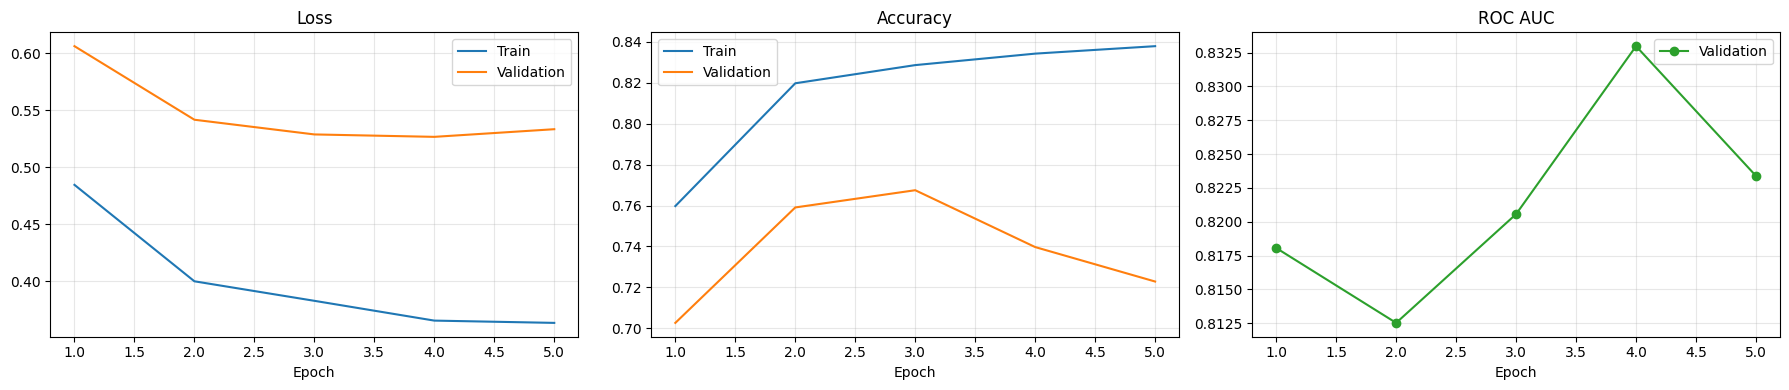

Epoch 5: loss=0.3633 acc=0.8379 val_loss=0.5332 val_acc=0.7228 val_auc=0.8234
335/335 ━━━━━━━━━━━━━━━━━━━━ 156s 465ms/step - acc: 0.8379 - loss: 0.3633 - val_acc: 0.7228 - val_loss: 0.5332


In [122]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('model/model_best.h5', monitor='acc', verbose=1, mode='max',save_best_only=True)
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min",restore_best_weights=True, patience=10)
live_plot = LivePlot(val_data)

callbacks_list = [checkpoint,early,live_plot]

# training the model
history = model.fit(                                                     
        aug_train_data,
        validation_data = val_data,
        epochs=5,                                                             
        shuffle=False,
        verbose=True,
        callbacks=callbacks_list
)

In [123]:
model = tf.keras.models.load_model('/kaggle/working/model/model_best.h5')

In [124]:
ytest = np.array([])                                                           
xtest = []                                                                     

for i in range(math.ceil(len(test_data.classes)/batch_size)):                  
    xtest.append(test_data[i][0])                                              
    ytest= np.concatenate((ytest,test_data[i][-1]))                            

xtest = np.concatenate((xtest),axis=0)                                         

ypred_prob_test =model.predict(xtest)                                    
ypred_test = (ypred_prob_test.ravel()>0.5).astype(int)               

63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 212ms/step


In [125]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
print(classification_report(ytest,ypred_test))

              precision    recall  f1-score   support

         0.0       0.79      0.87      0.83      1000
         1.0       0.86      0.77      0.81      1000

    accuracy                           0.82      2000
   macro avg       0.83      0.82      0.82      2000
weighted avg       0.83      0.82      0.82      2000



[Text(45.722222222222214, 0.5, 'True label')]

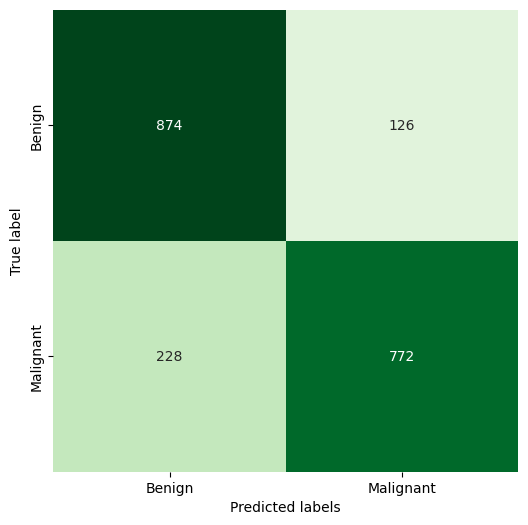

In [126]:
plt.figure(figsize=(6, 6))
hm = sns.heatmap(confusion_matrix(ytest, ypred_test), annot=True, vmin=0, fmt='g', cmap='Greens', cbar=False,xticklabels=['Benign','Malignant'],yticklabels=['Benign','Malignant'])
hm.set(xlabel='Predicted labels')
hm.set(ylabel='True label') 

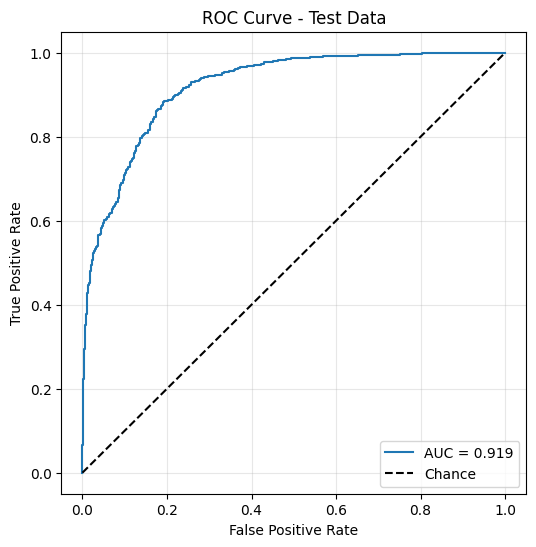

In [127]:
plot_roc_curve(ytest, ypred_prob_test.ravel(), title='ROC Curve - Test Data')

In [128]:
!pip install tf_keras_vis

Correct: Malignant


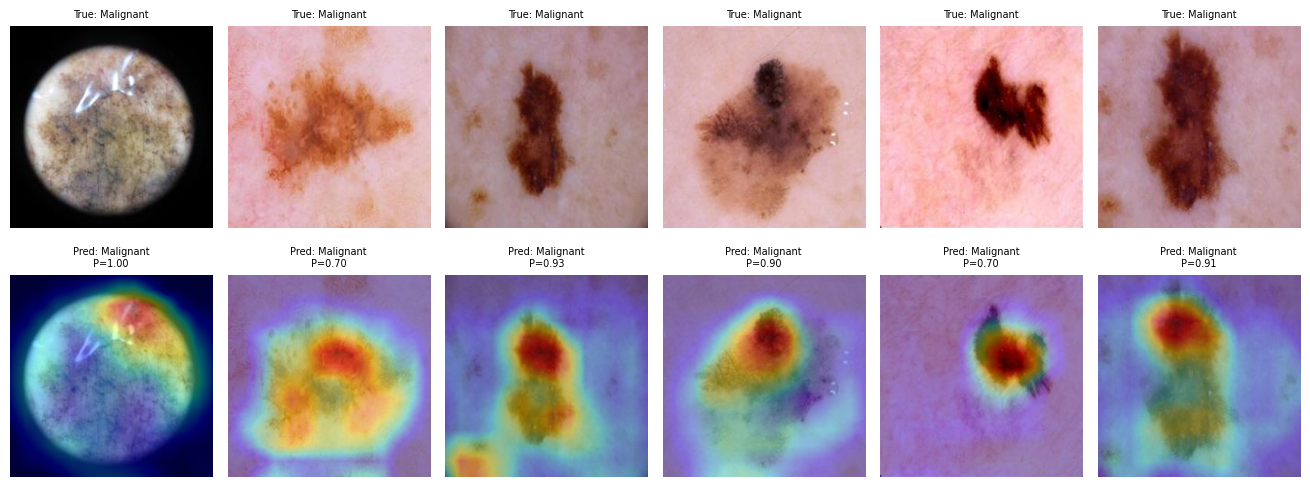

Correct: Benign


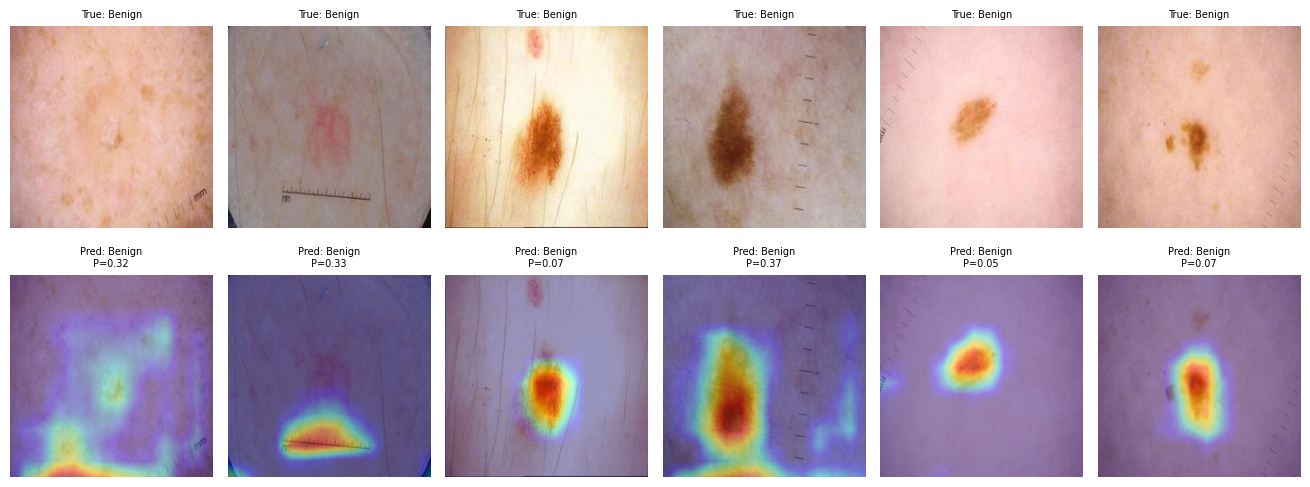

Mistake: False negative (malignant predicted benign)


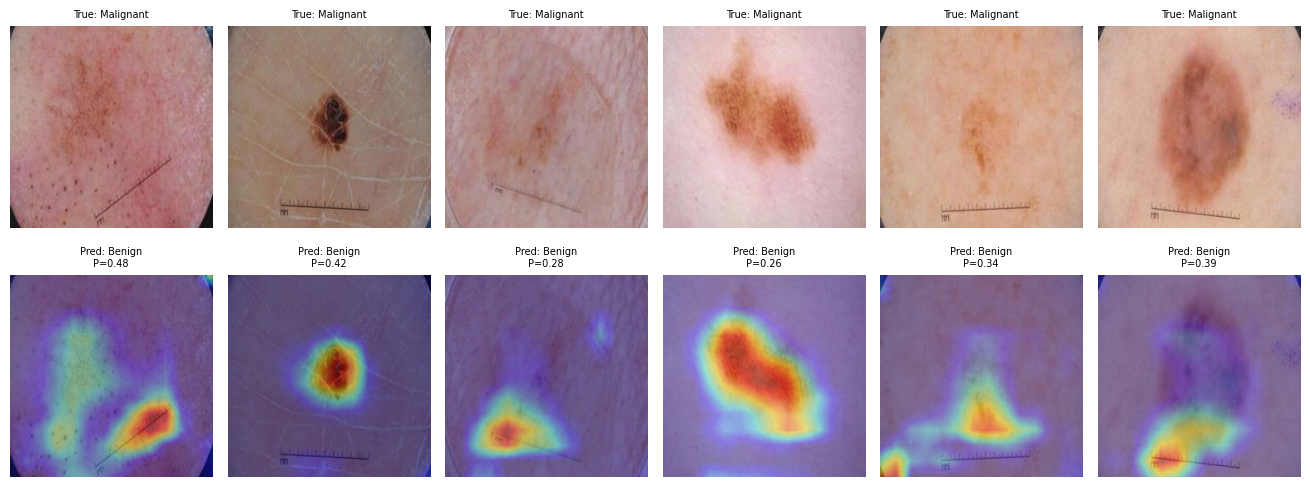

Mistake: False positive (benign predicted malignant)


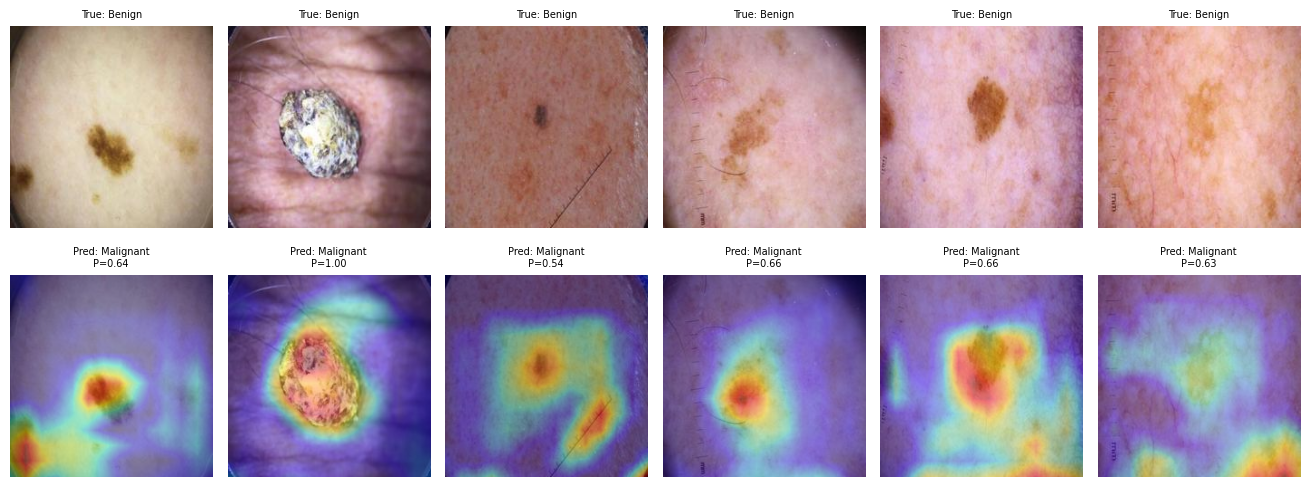

In [ ]:

# Grad-CAM using the tf-keras-vis library (Selvaraju et al., 2017). !pip install tf-keras-vis
from tf_keras_vis.gradcam import Gradcam
base = model.layers[0]
inp = tf.keras.Input(shape=base.input_shape[1:])
x = inp
for layer in base.layers[1:] + model.layers[1:]:
    new_layer = layer.__class__.from_config(layer.get_config())
    x = new_layer(x)
    new_layer.set_weights(layer.get_weights())
gradcam_model = tf.keras.Model(inp, x)

gradcam = Gradcam(gradcam_model, clone=False)
score = lambda output: output[:, 0]  

def plot_gradcam(images, labels, indices, threshold=0.5, alpha=0.4, size=2.2):
    batch = images[indices]
    cams = gradcam(score, batch, penultimate_layer='block5_conv3', seek_penultimate_conv_layer=False)
    probs = gradcam_model.predict(batch, verbose=0).ravel()

    fig, axes = plt.subplots(2, len(indices), figsize=(size * len(indices), 2 * size + 0.8), squeeze=False)
    for col, idx in enumerate(indices):
        pred = 'Malignant' if probs[col] > threshold else 'Benign'
        true = 'Malignant' if labels[idx] == 1 else 'Benign'
        axes[0][col].imshow(images[idx])
        axes[0][col].set_title(f"True: {true}", fontsize=7)
        axes[1][col].imshow(images[idx])
        axes[1][col].imshow(cams[col], cmap='jet', alpha=alpha)
        axes[1][col].set_title(f"Pred: {pred}\nP={probs[col]:.2f}", fontsize=7)
        axes[0][col].axis('off')
        axes[1][col].axis('off')
    plt.tight_layout()
    plt.show()
# Grad-CAM on 6 random test images from each group: correct predictions and mistakes
rng = np.random.default_rng(42)
tp = np.where((ytest == 1) & (ypred_test == 1))[0]  # malignant, predicted malignant
tn = np.where((ytest == 0) & (ypred_test == 0))[0]  # benign, predicted benign
fn = np.where((ytest == 1) & (ypred_test == 0))[0]  # malignant, predicted benign (false negative)
fp = np.where((ytest == 0) & (ypred_test == 1))[0]  # benign, predicted malignant (false positive)

for title, idxs in [('Correct: Malignant', tp), ('Correct: Benign', tn),
                    ('Mistake: False negative (malignant predicted benign)', fn),
                    ('Mistake: False positive (benign predicted malignant)', fp)]:
    print(title)
    plot_gradcam(xtest, ytest, rng.choice(idxs, min(6, len(idxs)), replace=False))

In [ ]:

train_noaug = ImageDataGenerator(rescale=1./255., validation_split=0.1).flow_from_directory(
    TRAINING_DIR, batch_size=batch_size, shuffle=False, class_mode='binary',
    target_size=(height, width), classes={'Benign': 0, 'Malignant': 1}, subset='training')
extractor = tf.keras.Sequential([model.layers[0], model.layers[1]])
X_tr, y_tr = extractor.predict(train_noaug), train_noaug.classes
X_val, y_val = extractor.predict(val_data), val_data.classes   # val_data must have shuffle=False

rows = []
for lr in [1e-2, 1e-3, 1e-4]:
    for w in [1.0, 1.5, 2.0]:
        tf.keras.utils.set_random_seed(42)
        head = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(512,)),
            tf.keras.layers.Dense(256, activation='relu'), tf.keras.layers.Dropout(0.5),
            tf.keras.layers.Dense(256, activation='relu'), tf.keras.layers.Dropout(0.5),
            tf.keras.layers.Dense(1, activation='sigmoid')])
        head.compile(loss='binary_crossentropy', optimizer=tf.keras.optimizers.Adam(lr))
        head.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=15, batch_size=64, verbose=0,
                 class_weight={0: 1.0, 1: w},
                 callbacks=[tf.keras.callbacks.EarlyStopping('val_loss', patience=3, restore_best_weights=True)])
        p = head.predict(X_val, verbose=0).ravel()
        for thr in [0.4, 0.45, 0.5]:
            pred = (p > thr).astype(int)
            rows.append(dict(lr=lr, malignant_weight=w, threshold=thr, val_auc=roc_auc_score(y_val, p),
                             val_acc=(pred == y_val).mean(),
                             malignant_recall=recall_score(y_val, pred),
                             benign_recall=recall_score(y_val, pred, pos_label=0)))
results = pd.DataFrame(rows)
results.sort_values('val_auc', ascending=False)

Found 10692 images belonging to 2 classes.
335/335 ━━━━━━━━━━━━━━━━━━━━ 70s 206ms/step
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 208ms/step


,lr,malignant_weight,threshold,val_auc,val_acc,malignant_recall,benign_recall
14,0.0010,1.5,0.50,0.856323,0.771693,0.737030,0.802548
13,0.0010,1.5,0.45,0.856323,0.779275,0.774597,0.783439
12,0.0010,1.5,0.40,0.856323,0.787700,0.806798,0.770701
15,0.0010,2.0,0.40,0.848381,0.791912,0.855098,0.735669
17,0.0010,2.0,0.50,0.848381,0.783488,0.810376,0.759554
16,0.0010,2.0,0.45,0.848381,0.791912,0.840787,0.748408
11,0.0010,1.0,0.50,0.848370,0.760741,0.711986,0.804140
10,0.0010,1.0,0.45,0.848370,0.770008,0.754919,0.783439
9,0.0010,1.0,0.40,0.848370,0.778433,0.788909,0.769108
2,0.0100,1.0,0.50,0.842929,0.732940,0.629696,0.824841


In [131]:
results=results[results["malignant_recall"]>0.8]
results=results[results["benign_recall"]>0.7]

In [132]:
results

,lr,malignant_weight,threshold,val_auc,val_acc,malignant_recall,benign_recall
4,0.010,1.5,0.45,0.836544,0.776748,0.856887,0.705414
8,0.010,2.0,0.50,0.841825,0.782645,0.865832,0.708599
12,0.001,1.5,0.40,0.856323,0.787700,0.806798,0.770701
15,0.001,2.0,0.40,0.848381,0.791912,0.855098,0.735669
16,0.001,2.0,0.45,0.848381,0.791912,0.840787,0.748408
17,0.001,2.0,0.50,0.848381,0.783488,0.810376,0.759554


Based on the table above, the best learning rate seems to be 1e-3 since it has the most entries on this list.. Setting this as the learning rate, I will set a 2.0 malignant weight and a threshold of 0.4 to be considered malignant instead of 0.5. This is because it has the highest acuracy and malignant recall for rows with this learning rate. I will take these values an put them into the new model.

I am also reducing epochs to 3 since that it is where it peaked in the model before overfitting.

In [133]:
tf.keras.backend.clear_session()                                               

input_shape = (height, width, 3)                                               
base_model = tf.keras.applications.vgg16.VGG16(
    weights='imagenet',                                                        
    include_top=False,                                                         
    input_shape=input_shape
)
base_model.trainable = False                                                  
tuned_model = tf.keras.Sequential()                                            
tuned_model.add(base_model)                                                   
tuned_model.add(tf.keras.layers.GlobalAveragePooling2D())                     
tuned_model.add(tf.keras.layers.Flatten())                                     
tuned_model.add(tf.keras.layers.Dense(256, activation='relu'))                 
tuned_model.add(tf.keras.layers.Dropout(0.5))                                 
tuned_model.add(tf.keras.layers.Dense(256, activation='relu'))
tuned_model.add(tf.keras.layers.Dropout(0.5))

tuned_model.add(tf.keras.layers.Dense(1, activation='sigmoid'))            
tuned_model.compile(loss='BinaryCrossentropy',                     
              optimizer=tf.keras.optimizers.Adam(0.001),
              metrics=([tf.keras.metrics.BinaryAccuracy(name='acc',threshold=0.4)]))                                               
tuned_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,912,065 (56.89 MB)

 Trainable params: 197,377 (771.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

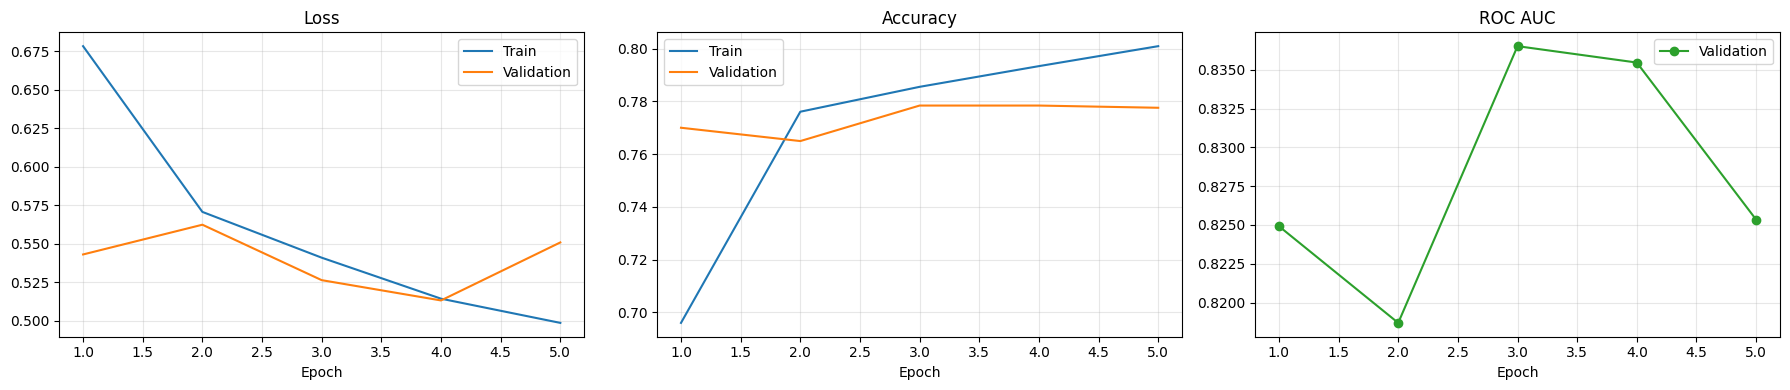

Epoch 5: loss=0.4988 acc=0.8010 val_loss=0.5510 val_acc=0.7776 val_auc=0.8253
335/335 ━━━━━━━━━━━━━━━━━━━━ 167s 499ms/step - acc: 0.8010 - loss: 0.4988 - val_acc: 0.7776 - val_loss: 0.5510


In [134]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('model/tuned_model_best.h5', monitor='acc', verbose=1, mode='max',save_best_only=True)
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min",restore_best_weights=True, patience=10)
live_plot = LivePlot(val_data)
class_weight = {0: 1.0, 1: 2.0}
callbacks_list = [checkpoint,early,live_plot]

history = tuned_model.fit(                                                     
        aug_train_data,
        validation_data = val_data,
        epochs=5,                                                             
        shuffle=False,
        verbose=True,
        callbacks=callbacks_list,
        class_weight=class_weight
)

In [135]:
tuned_model = tf.keras.models.load_model('/kaggle/working/model/tuned_model_best.h5')

In [136]:
ytest = np.array([])                                                           
xtest = []                                                                     

for i in range(math.ceil(len(test_data.classes)/batch_size)):                  
    xtest.append(test_data[i][0])                                              
    ytest= np.concatenate((ytest,test_data[i][-1]))                            

xtest = np.concatenate((xtest),axis=0)                                         

ypred_prob_test =tuned_model.predict(xtest)                                    
ypred_test = (ypred_prob_test.ravel()>0.4).astype(int)        

63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 209ms/step


In [137]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
print(classification_report(ytest,ypred_test))

              precision    recall  f1-score   support

         0.0       0.94      0.69      0.80      1000
         1.0       0.76      0.95      0.84      1000

    accuracy                           0.82      2000
   macro avg       0.85      0.82      0.82      2000
weighted avg       0.85      0.82      0.82      2000



[Text(45.722222222222214, 0.5, 'True label')]

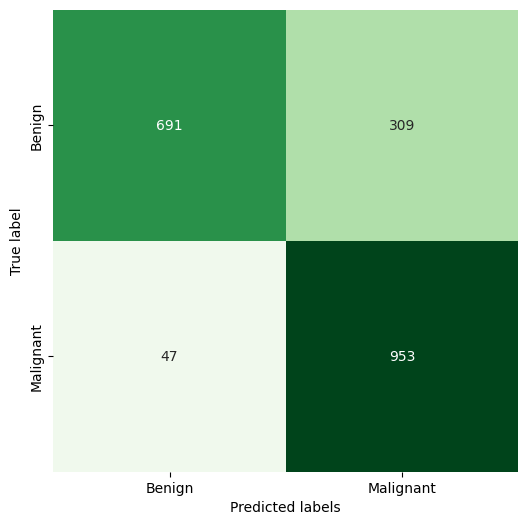

In [138]:
plt.figure(figsize=(6, 6))
hm = sns.heatmap(confusion_matrix(ytest, ypred_test), annot=True, vmin=0, fmt='g', cmap='Greens', cbar=False,xticklabels=['Benign','Malignant'],yticklabels=['Benign','Malignant'])
hm.set(xlabel='Predicted labels')
hm.set(ylabel='True label') 

Conducting hyperparameter tuning kept the accuracy very similar, but was able to greatly reduce the amount of malignant images predicted as benign.